# Cadrage : est-ce que l’objet rentre dans le capteur ?

Ce notebook :
1. répertorie les **télescopes, caméras et télescopes intelligents** les plus courants ;
2. calcule le **champ de vision** d’une combinaison télescope + caméra ;
3. dit si un objet céleste **rentre bien dans le cadre**, ou s’il est **trop grand / trop petit** pour cette focale.

Chaque cellule définit une seule chose. La **dernière cellule** assemble toutes les fonctions dans `analyser(...)`.

## 1. Imports

In [1]:
import math
import unicodedata

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Rectangle

## 2. Catalogue des télescopes et objectifs

Diamètre et focale en mm (données constructeur).

In [2]:
TELESCOPES = {
    'Sky-Watcher 130PDS':          {'type': 'Newton',              'diametre_mm': 130,  'focale_mm': 650},
    'Sky-Watcher 150PDS':          {'type': 'Newton',              'diametre_mm': 150,  'focale_mm': 750},
    'Sky-Watcher 200PDS':          {'type': 'Newton',              'diametre_mm': 200,  'focale_mm': 1000},
    'Sky-Watcher Evostar 72ED':    {'type': 'Lunette',             'diametre_mm': 72,   'focale_mm': 420},
    'Sky-Watcher Evostar 80ED':    {'type': 'Lunette',             'diametre_mm': 80,   'focale_mm': 600},
    'William Optics RedCat 51':    {'type': 'Lunette',             'diametre_mm': 51,   'focale_mm': 250},
    'Askar FRA400':                {'type': 'Lunette',             'diametre_mm': 72,   'focale_mm': 400},
    'Sky-Watcher Skymax 127':      {'type': 'Maksutov',            'diametre_mm': 127,  'focale_mm': 1500},
    'Celestron NexStar 8SE':       {'type': 'Schmidt-Cassegrain',  'diametre_mm': 203,  'focale_mm': 2032},
    'Celestron RASA 8':            {'type': 'Rowe-Ackermann',      'diametre_mm': 203,  'focale_mm': 400},
    'Samyang 135mm f/2':           {'type': 'Objectif photo',      'diametre_mm': 67.5, 'focale_mm': 135},
    'Canon EF 200mm f/2.8L':       {'type': 'Objectif photo',      'diametre_mm': 71,   'focale_mm': 200},
}

print(len(TELESCOPES), 'télescopes :', ', '.join(TELESCOPES))

12 télescopes : Sky-Watcher 130PDS, Sky-Watcher 150PDS, Sky-Watcher 200PDS, Sky-Watcher Evostar 72ED, Sky-Watcher Evostar 80ED, William Optics RedCat 51, Askar FRA400, Sky-Watcher Skymax 127, Celestron NexStar 8SE, Celestron RASA 8, Samyang 135mm f/2, Canon EF 200mm f/2.8L


## 3. Catalogue des caméras

Taille du capteur en mm, taille des pixels en microns, résolution en pixels.

In [3]:
CAMERAS = {
    'ZWO ASI120MC':      {'type': 'Caméra planétaire',      'largeur_mm': 4.8,  'hauteur_mm': 3.6,  'pixel_um': 3.75, 'resolution': (1280, 960)},
    'ZWO ASI224MC':      {'type': 'Caméra planétaire',      'largeur_mm': 4.9,  'hauteur_mm': 3.7,  'pixel_um': 3.75, 'resolution': (1304, 976)},
    'ZWO ASI462MC':      {'type': 'Caméra planétaire',      'largeur_mm': 5.6,  'hauteur_mm': 3.2,  'pixel_um': 2.9,  'resolution': (1936, 1096)},
    'ZWO ASI533MC Pro':  {'type': 'Caméra astro refroidie', 'largeur_mm': 11.3, 'hauteur_mm': 11.3, 'pixel_um': 3.76, 'resolution': (3008, 3008)},
    'ZWO ASI294MC Pro':  {'type': 'Caméra astro refroidie', 'largeur_mm': 19.1, 'hauteur_mm': 13.0, 'pixel_um': 4.63, 'resolution': (4144, 2822)},
    'ZWO ASI2600MC Pro': {'type': 'Caméra astro refroidie', 'largeur_mm': 23.5, 'hauteur_mm': 15.7, 'pixel_um': 3.76, 'resolution': (6248, 4176)},
    'ZWO ASI6200MC Pro': {'type': 'Caméra astro refroidie', 'largeur_mm': 36.0, 'hauteur_mm': 24.0, 'pixel_um': 3.76, 'resolution': (9576, 6388)},
    'Canon EOS 2000D':   {'type': 'Reflex APS-C',           'largeur_mm': 22.3, 'hauteur_mm': 14.9, 'pixel_um': 3.72, 'resolution': (6000, 4000)},
    'Nikon D5300':       {'type': 'Reflex APS-C',           'largeur_mm': 23.5, 'hauteur_mm': 15.6, 'pixel_um': 3.92, 'resolution': (6000, 4000)},
    'Canon EOS 6D':      {'type': 'Reflex plein format',    'largeur_mm': 35.8, 'hauteur_mm': 23.9, 'pixel_um': 6.55, 'resolution': (5472, 3648)},
    'Sony A7 III':       {'type': 'Hybride plein format',   'largeur_mm': 35.6, 'hauteur_mm': 23.8, 'pixel_um': 5.9,  'resolution': (6000, 4000)},
}

print(len(CAMERAS), 'caméras :', ', '.join(CAMERAS))

11 caméras : ZWO ASI120MC, ZWO ASI224MC, ZWO ASI462MC, ZWO ASI533MC Pro, ZWO ASI294MC Pro, ZWO ASI2600MC Pro, ZWO ASI6200MC Pro, Canon EOS 2000D, Nikon D5300, Canon EOS 6D, Sony A7 III


## 4. Télescopes intelligents

Optique et capteur sont intégrés : on ne choisit pas de caméra et on ne peut pas ajouter d’accessoire.

In [4]:
TELESCOPES_INTELLIGENTS = {
    'ZWO Seestar S50': {'type': 'Télescope intelligent', 'diametre_mm': 50, 'focale_mm': 250,
                        'largeur_mm': 5.57, 'hauteur_mm': 3.13, 'pixel_um': 2.9, 'resolution': (1920, 1080)},
    'Vaonis Vespera':  {'type': 'Télescope intelligent', 'diametre_mm': 50, 'focale_mm': 200,
                        'largeur_mm': 5.57, 'hauteur_mm': 3.13, 'pixel_um': 2.9, 'resolution': (1920, 1080)},
}

print(len(TELESCOPES_INTELLIGENTS), 'télescopes intelligents :', ', '.join(TELESCOPES_INTELLIGENTS))

2 télescopes intelligents : ZWO Seestar S50, Vaonis Vespera


## 5. Accessoires

Un réducteur raccourcit la focale (champ plus large), une Barlow l’allonge (champ plus serré).

In [5]:
ACCESSOIRES = {
    'aucun':           {'facteur': 1.0},
    'Réducteur 0.8x':  {'facteur': 0.8},
    'Réducteur 0.63x': {'facteur': 0.63},
    'Barlow 2x':       {'facteur': 2.0},
}

print(len(ACCESSOIRES), 'accessoires :', ', '.join(ACCESSOIRES))

4 accessoires : aucun, Réducteur 0.8x, Réducteur 0.63x, Barlow 2x


## 6. Objets célestes

Taille apparente (grand axe x petit axe) en minutes d’arc, valeurs approximatives. Repère : la pleine Lune fait environ 31′.

In [6]:
OBJETS = {
    'M1':      {'nom': 'Nébuleuse du Crabe',        'taille_max_arcmin': 6.0,   'taille_min_arcmin': 4.0},
    'M13':     {'nom': 'Amas d’Hercule',            'taille_max_arcmin': 20.0,  'taille_min_arcmin': 20.0},
    'M27':     {'nom': 'Nébuleuse de l’Haltère',    'taille_max_arcmin': 8.0,   'taille_min_arcmin': 5.7},
    'M31':     {'nom': 'Galaxie d’Andromède',       'taille_max_arcmin': 178.0, 'taille_min_arcmin': 70.0},
    'M33':     {'nom': 'Galaxie du Triangle',       'taille_max_arcmin': 71.0,  'taille_min_arcmin': 42.0},
    'M42':     {'nom': 'Grande nébuleuse d’Orion',  'taille_max_arcmin': 85.0,  'taille_min_arcmin': 60.0},
    'M45':     {'nom': 'Pléiades',                  'taille_max_arcmin': 110.0, 'taille_min_arcmin': 110.0},
    'M51':     {'nom': 'Galaxie du Tourbillon',     'taille_max_arcmin': 11.0,  'taille_min_arcmin': 7.0},
    'M57':     {'nom': 'Nébuleuse de la Lyre',      'taille_max_arcmin': 1.4,   'taille_min_arcmin': 1.0},
    'M81':     {'nom': 'Galaxie de Bode',           'taille_max_arcmin': 27.0,  'taille_min_arcmin': 14.0},
    'M101':    {'nom': 'Galaxie du Moulinet',       'taille_max_arcmin': 29.0,  'taille_min_arcmin': 27.0},
    'M104':    {'nom': 'Galaxie du Sombrero',       'taille_max_arcmin': 8.7,   'taille_min_arcmin': 3.5},
    'NGC7000': {'nom': 'Nébuleuse North America',   'taille_max_arcmin': 120.0, 'taille_min_arcmin': 100.0},
    'C14':     {'nom': 'Double amas de Persée',     'taille_max_arcmin': 60.0,  'taille_min_arcmin': 30.0},
    'Lune':    {'nom': 'Pleine Lune',               'taille_max_arcmin': 31.0,  'taille_min_arcmin': 31.0},
}

print(len(OBJETS), 'objets :', ', '.join(OBJETS))

15 objets : M1, M13, M27, M31, M33, M42, M45, M51, M57, M81, M101, M104, NGC7000, C14, Lune


## 7. Recherche par nom

Retrouve une entrée d’un catalogue sans tenir compte des majuscules, espaces, tirets et accents.
Un nom partiel marche s’il fait au moins 4 caractères et ne correspond qu’à une seule entrée (`'redcat'`, `'andromede'`, `'barlow'`).

In [7]:
def _normaliser(texte):
    texte = unicodedata.normalize('NFKD', texte)
    texte = ''.join(c for c in texte if not unicodedata.combining(c))
    return texte.lower().replace(' ', '').replace('-', '').replace('_', '')


def trouver(nom, catalogue):
    cle = _normaliser(nom)
    for k, v in catalogue.items():
        if cle == _normaliser(k):
            return k, v
    candidats = []
    if len(cle) >= 4:
        candidats = [k for k, v in catalogue.items()
                     if cle in _normaliser(k) or cle in _normaliser(v.get('nom', ''))]
    if len(candidats) == 1:
        return candidats[0], catalogue[candidats[0]]
    raise ValueError(f'{nom!r} introuvable ou ambigu. Choix possibles : {list(catalogue)}')


trouver('redcat', TELESCOPES)

('William Optics RedCat 51',
 {'type': 'Lunette', 'diametre_mm': 51, 'focale_mm': 250})

## 8. Assemblage du matériel

Combine télescope + caméra + accessoire et calcule la **focale effective** (focale x facteur de l’accessoire).

In [8]:
def configuration(telescope, camera=None, accessoire='aucun'):
    try:
        nom_tel, tel = trouver(telescope, TELESCOPES_INTELLIGENTS)
        nom_cam, capteur = 'capteur intégré', tel
        nom_acc, facteur = 'aucun', 1.0  # pas d’accessoire sur un télescope intelligent
    except ValueError:
        nom_tel, tel = trouver(telescope, TELESCOPES)
        if camera is None:
            raise ValueError(f'Préciser une caméra pour {nom_tel}.')
        nom_cam, capteur = trouver(camera, CAMERAS)
        nom_acc, acc = trouver(accessoire, ACCESSOIRES)
        facteur = acc['facteur']

    nom = f'{nom_tel} + {nom_cam}'
    if facteur != 1.0:
        nom += f' + {nom_acc}'
    return {
        'nom': nom,
        'focale_mm': tel['focale_mm'] * facteur,
        'diametre_mm': tel['diametre_mm'],
        'largeur_mm': capteur['largeur_mm'],
        'hauteur_mm': capteur['hauteur_mm'],
        'pixel_um': capteur['pixel_um'],
    }


configuration('Evostar 72ED', 'Canon EOS 2000D', 'Réducteur 0.8x')

{'nom': 'Sky-Watcher Evostar 72ED + Canon EOS 2000D + Réducteur 0.8x',
 'focale_mm': 336.0,
 'diametre_mm': 72,
 'largeur_mm': 22.3,
 'hauteur_mm': 14.9,
 'pixel_um': 3.72}

## 9. Champ de vision

Angle couvert par un côté du capteur : `angle = 2 x arctan(taille capteur / (2 x focale))`, converti en minutes d’arc.
La largeur est toujours le plus grand côté du capteur.

In [9]:
def angle_arcmin(taille_mm, focale_mm):
    return math.degrees(2 * math.atan(taille_mm / (2 * focale_mm))) * 60


def champ_de_vision(config):
    f = config['focale_mm']
    grand_cote = max(config['largeur_mm'], config['hauteur_mm'])
    petit_cote = min(config['largeur_mm'], config['hauteur_mm'])
    return {
        'largeur_arcmin': angle_arcmin(grand_cote, f),
        'hauteur_arcmin': angle_arcmin(petit_cote, f),
        'diagonale_arcmin': angle_arcmin(math.hypot(grand_cote, petit_cote), f),
    }


champ_de_vision(configuration('Evostar 72ED', 'Canon EOS 2000D'))

{'largeur_arcmin': 182.48512097749747,
 'hauteur_arcmin': 121.94537069079993,
 'diagonale_arcmin': 219.44824505123137}

## 10. Échantillonnage

Portion de ciel vue par un pixel, en secondes d’arc : `206.265 x taille pixel (µm) / focale (mm)`.
Il sert à savoir combien de pixels l’objet couvre sur l’image.

In [10]:
def echantillonnage(config):
    return 206.265 * config['pixel_um'] / config['focale_mm']


echantillonnage(configuration('Evostar 72ED', 'Canon EOS 2000D'))

1.8269185714285714

## 11. Verdict de cadrage

On tourne la caméra pour aligner le grand axe de l’objet sur le grand côté du capteur, puis on mesure la part du cadre qu’il occupe :

| Remplissage | Verdict |
|---|---|
| plus de 100 % | **TROP GRAND** : l’objet déborde |
| 80 à 100 % | **RENTRE JUSTE** : peu de marge autour |
| 30 à 80 % | **IDÉAL** |
| moins de 30 %, mais au moins 150 px | **PETIT** : recadrage possible |
| moins de 30 % et moins de 150 px | **TROP PETIT** : pas assez de détails |

In [11]:
def evaluer_cadrage(objet, champ, echant_arcsec):
    grand = objet['taille_max_arcmin']
    petit = objet['taille_min_arcmin']
    remplissage = max(grand / champ['largeur_arcmin'], petit / champ['hauteur_arcmin'])
    taille_px = grand * 60 / echant_arcsec

    if remplissage > 1:
        verdict = 'TROP GRAND'
    elif remplissage >= 0.8:
        verdict = 'RENTRE JUSTE'
    elif remplissage >= 0.3:
        verdict = 'IDÉAL'
    elif taille_px >= 150:
        verdict = 'PETIT'
    else:
        verdict = 'TROP PETIT'
    return {'verdict': verdict, 'remplissage': remplissage, 'taille_px': taille_px}


config_test = configuration('Evostar 72ED', 'Canon EOS 2000D')
evaluer_cadrage(OBJETS['M42'], champ_de_vision(config_test), echantillonnage(config_test))

{'verdict': 'IDÉAL',
 'remplissage': 0.4920235976167864,
 'taille_px': 2791.5858318808487}

## 12. Mosaïque

Quand l’objet est trop grand : nombre de panneaux (largeur x hauteur) pour le couvrir, avec 15 % de recouvrement entre les panneaux.

In [12]:
def mosaique(objet, champ, recouvrement=0.15):
    utile_larg = champ['largeur_arcmin'] * (1 - recouvrement)
    utile_haut = champ['hauteur_arcmin'] * (1 - recouvrement)
    nx = max(1, math.ceil(objet['taille_max_arcmin'] / utile_larg))
    ny = max(1, math.ceil(objet['taille_min_arcmin'] / utile_haut))
    return nx, ny


config_test = configuration('ZWO Seestar S50')
mosaique(OBJETS['M31'], champ_de_vision(config_test))

(3, 2)

## 13. Conseil

Traduit le verdict en conseil concret : mosaïque, réducteur, Barlow ou focale à viser.

In [13]:
def conseil(evaluation, config, objet, champ):
    f = config['focale_mm']
    r = evaluation['remplissage']
    px = evaluation['taille_px']
    verdict = evaluation['verdict']

    if verdict == 'TROP GRAND':
        nx, ny = mosaique(objet, champ)
        return (f'L’objet déborde du cadre : mosaïque de {nx} x {ny} panneaux, '
                f'ou focale de {f / r * 0.9:.0f} mm maximum pour qu’il rentre en entier.')
    if verdict == 'RENTRE JUSTE':
        return (f'L’objet rentre mais avec peu de marge. Un réducteur 0.8x '
                f'({f * 0.8:.0f} mm) laisserait plus de fond de ciel autour.')
    if verdict == 'IDÉAL':
        return 'Cadrage équilibré : l’objet remplit bien le capteur avec du fond de ciel autour.'
    if verdict == 'PETIT':
        return (f'L’objet est petit dans le champ mais assez résolu ({px:.0f} px) pour être recadré. '
                f'Pour l’agrandir : Barlow 2x ({f * 2:.0f} mm).')
    return (f'L’objet ne couvre que {px:.0f} px : trop petit pour ce matériel. '
            f'Viser une focale d’au moins {f * 150 / px:.0f} mm.')

## 14. Dessin du cadre

Rectangle bleu = champ du capteur, ellipse orange = objet, à la même échelle (minutes d’arc).

In [14]:
def dessiner_cadre(nom_objet, objet, champ, titre=''):
    larg, haut = champ['largeur_arcmin'], champ['hauteur_arcmin']
    grand, petit = objet['taille_max_arcmin'], objet['taille_min_arcmin']

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.add_patch(Rectangle((-larg / 2, -haut / 2), larg, haut, fill=False, lw=2,
                           color='tab:blue', label='Champ du capteur'))
    ax.add_patch(Ellipse((0, 0), grand, petit, color='tab:orange', alpha=0.5, label=nom_objet))

    lim = max(larg, haut, grand, petit) * 0.6
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.set_xlabel('arcminutes')
    ax.set_ylabel('arcminutes')
    ax.set_title(titre)
    ax.legend(loc='upper right')
    plt.show()

## 15. Meilleures combinaisons du catalogue

Teste toutes les combinaisons télescope + caméra (sans accessoire) et télescopes intelligents, et garde celles où l’objet est **IDÉAL**, en commençant par celles qui le font remplir environ 55 % du cadre.

In [15]:
def meilleures_combinaisons(nom_objet, top=5):
    _, objet = trouver(nom_objet, OBJETS)
    combinaisons = [(t, c) for t in TELESCOPES for c in CAMERAS]
    combinaisons += [(t, None) for t in TELESCOPES_INTELLIGENTS]

    resultats = []
    for tel, cam in combinaisons:
        config = configuration(tel, cam)
        evaluation = evaluer_cadrage(objet, champ_de_vision(config), echantillonnage(config))
        if evaluation['verdict'] == 'IDÉAL':
            ecart = abs(evaluation['remplissage'] - 0.55)
            resultats.append((ecart, config['nom'], evaluation['remplissage']))

    resultats.sort()
    return [(nom, remplissage) for _, nom, remplissage in resultats[:top]]

## 16. Bloc final : analyse complète

`analyser(objet, telescope, camera=None, accessoire='aucun')` enchaîne toutes les fonctions précédentes.

- `objet` : un nom du catalogue (`'M31'`, `'andromede'`…) ou un dictionnaire `{'taille_max_arcmin': ..., 'taille_min_arcmin': ...}` pour un objet hors catalogue.
- `camera` : inutile pour un télescope intelligent.

Objet           : M31 (Galaxie d’Andromède), 178.0′ x 70.0′
Matériel        : ZWO Seestar S50 + capteur intégré
Focale          : 250 mm (f/5.0)
Champ           : 76.6′ x 43.0′ (1.28° x 0.72°)
Échantillonnage : 2.39″/pixel
Remplissage     : 232 % du cadre (4464 px)
Verdict         : TROP GRAND
Conseil         : L’objet déborde du cadre : mosaïque de 3 x 2 panneaux, ou focale de 97 mm maximum pour qu’il rentre en entier.


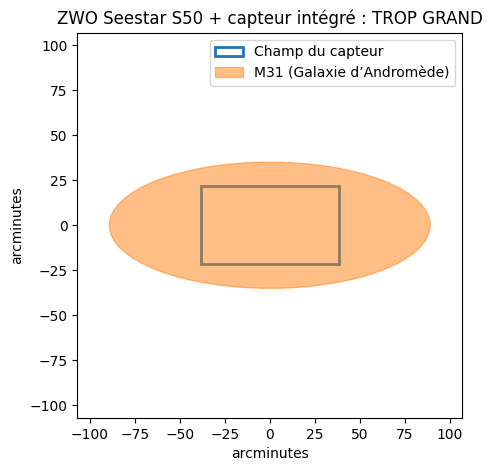

Objet           : M31 (Galaxie d’Andromède), 178.0′ x 70.0′
Matériel        : William Optics RedCat 51 + Canon EOS 6D
Focale          : 250 mm (f/4.9)
Champ           : 491.4′ x 328.4′ (8.19° x 5.47°)
Échantillonnage : 5.40″/pixel
Remplissage     : 36 % du cadre (1976 px)
Verdict         : IDÉAL
Conseil         : Cadrage équilibré : l’objet remplit bien le capteur avec du fond de ciel autour.


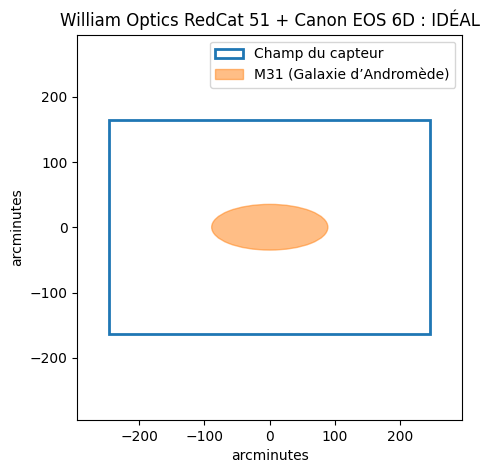

Objet           : M42 (Grande nébuleuse d’Orion), 85.0′ x 60.0′
Matériel        : Sky-Watcher Evostar 72ED + Canon EOS 2000D
Focale          : 420 mm (f/5.8)
Champ           : 182.5′ x 121.9′ (3.04° x 2.03°)
Échantillonnage : 1.83″/pixel
Remplissage     : 49 % du cadre (2792 px)
Verdict         : IDÉAL
Conseil         : Cadrage équilibré : l’objet remplit bien le capteur avec du fond de ciel autour.


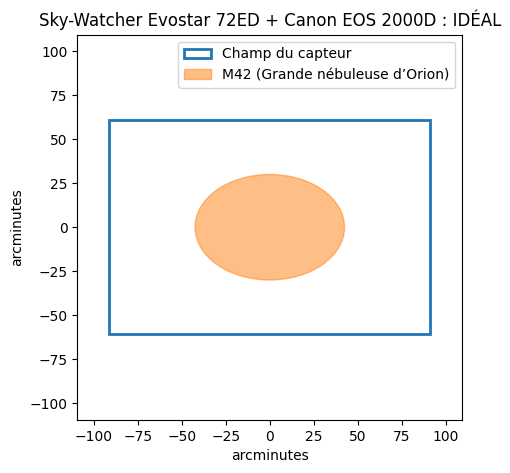

Objet           : M57 (Nébuleuse de la Lyre), 1.4′ x 1.0′
Matériel        : Celestron NexStar 8SE + ZWO ASI533MC Pro
Focale          : 2032 mm (f/10.0)
Champ           : 19.1′ x 19.1′ (0.32° x 0.32°)
Échantillonnage : 0.38″/pixel
Remplissage     : 7 % du cadre (220 px)
Verdict         : PETIT
Conseil         : L’objet est petit dans le champ mais assez résolu (220 px) pour être recadré. Pour l’agrandir : Barlow 2x (4064 mm).


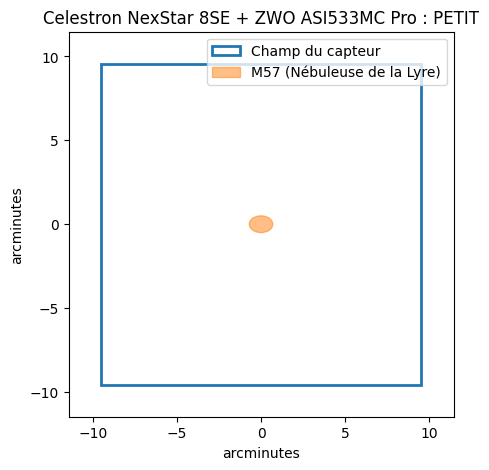

Objet           : M57 (Nébuleuse de la Lyre), 1.4′ x 1.0′
Matériel        : William Optics RedCat 51 + ZWO ASI2600MC Pro
Focale          : 250 mm (f/4.9)
Champ           : 322.9′ x 215.8′ (5.38° x 3.60°)
Échantillonnage : 3.10″/pixel
Remplissage     : 0 % du cadre (27 px)
Verdict         : TROP PETIT
Conseil         : L’objet ne couvre que 27 px : trop petit pour ce matériel. Viser une focale d’au moins 1385 mm.


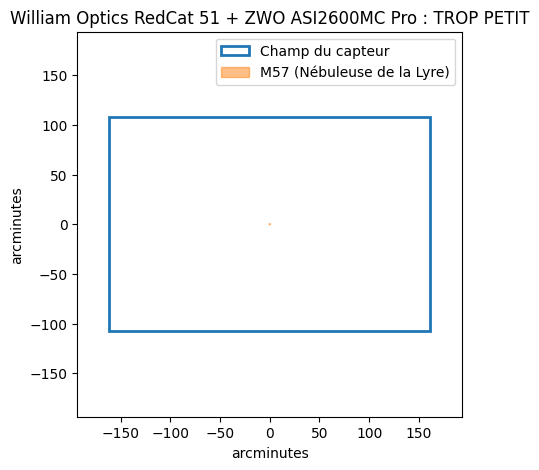

Objet           : Objet personnalisé, 30′ x 20′
Matériel        : Sky-Watcher 150PDS + Nikon D5300 + Barlow 2x
Focale          : 1500 mm (f/10.0)
Champ           : 53.9′ x 35.8′ (0.90° x 0.60°)
Échantillonnage : 0.54″/pixel
Remplissage     : 56 % du cadre (3339 px)
Verdict         : IDÉAL
Conseil         : Cadrage équilibré : l’objet remplit bien le capteur avec du fond de ciel autour.


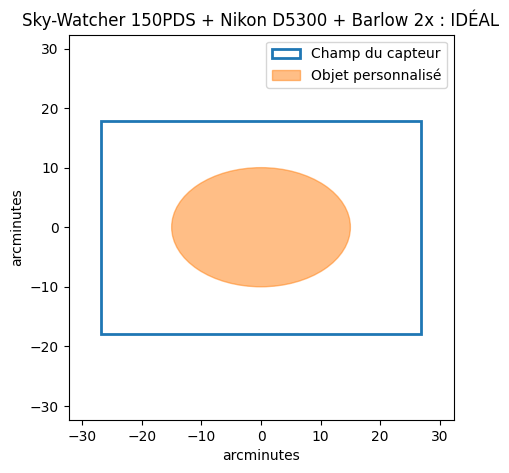

Meilleures combinaisons du catalogue pour M31 :
   55 %  William Optics RedCat 51 + Nikon D5300
   55 %  William Optics RedCat 51 + ZWO ASI2600MC Pro
   54 %  Canon EF 200mm f/2.8L + ZWO ASI294MC Pro
   58 %  Askar FRA400 + ZWO ASI6200MC Pro
   58 %  Celestron RASA 8 + ZWO ASI6200MC Pro


In [17]:
def analyser(objet, telescope, camera=None, accessoire='aucun', dessiner=True):
    if isinstance(objet, str):
        cle, donnees = trouver(objet, OBJETS)
        nom_objet = cle + ' (' + donnees['nom'] + ')'
    else:
        nom_objet, donnees = 'Objet personnalisé', objet

    config = configuration(telescope, camera, accessoire)
    champ = champ_de_vision(config)
    echant = echantillonnage(config)
    evaluation = evaluer_cadrage(donnees, champ, echant)
    texte_conseil = conseil(evaluation, config, donnees, champ)

    nom_config = config['nom']
    f, d = config['focale_mm'], config['diametre_mm']
    larg, haut = champ['largeur_arcmin'], champ['hauteur_arcmin']
    grand, petit = donnees['taille_max_arcmin'], donnees['taille_min_arcmin']
    verdict = evaluation['verdict']
    remplissage, px = evaluation['remplissage'], evaluation['taille_px']

    print(f'Objet           : {nom_objet}, {grand}′ x {petit}′')
    print(f'Matériel        : {nom_config}')
    print(f'Focale          : {f:.0f} mm (f/{f / d:.1f})')
    print(f'Champ           : {larg:.1f}′ x {haut:.1f}′ ({larg / 60:.2f}° x {haut / 60:.2f}°)')
    print(f'Échantillonnage : {echant:.2f}″/pixel')
    print(f'Remplissage     : {remplissage * 100:.0f} % du cadre ({px:.0f} px)')
    print(f'Verdict         : {verdict}')
    print(f'Conseil         : {texte_conseil}')
    if dessiner:
        dessiner_cadre(nom_objet, donnees, champ, titre=nom_config + ' : ' + verdict)
    return evaluation


# --- Exemples ---
analyser('M31', 'ZWO Seestar S50')                              # trop grand -> mosaïque
analyser('M31', 'RedCat 51', 'Canon EOS 6D')                    # grand champ : idéal
analyser('M42', 'Evostar 72ED', 'Canon EOS 2000D')              # idéal
analyser('M57', 'NexStar 8SE', 'ASI533MC')                      # petit mais recadrable
analyser('M57', 'RedCat 51', 'ASI2600MC')                       # trop petit
analyser({'taille_max_arcmin': 30, 'taille_min_arcmin': 20}, 'Sky-Watcher 150PDS', 'Nikon D5300', 'Barlow 2x')

print('Meilleures combinaisons du catalogue pour M31 :')
for nom, remplissage in meilleures_combinaisons('M31'):
    print(f'  {remplissage * 100:3.0f} %  {nom}')